In [ ]:
# ============================================================
# CELL 1 - Gerekli kütüphaneler
# ============================================================

!pip -q install boto3 rasterio geopandas shapely pyproj scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 4.0 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 2 - Imports
# ============================================================

import os
import re
import json
import random
import glob
import warnings
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
from rasterio.features import rasterize

from shapely.geometry import shape

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Sabitler
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

IMAGE_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 20
LEARNING_RATE = 1e-3

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# CELL 3 - Proje klasörleri
# ============================================================

BASE_DIR = "/content/geoai_project"

IMAGE_DIR = os.path.join(BASE_DIR, "images")
GEOJSON_DIR = os.path.join(BASE_DIR, "geojson")
MASK_DIR = os.path.join(BASE_DIR, "masks")
RESULT_DIR = os.path.join(BASE_DIR, "results")

for directory in [
    BASE_DIR,
    IMAGE_DIR,
    GEOJSON_DIR,
    MASK_DIR,
    RESULT_DIR
]:
    os.makedirs(directory, exist_ok=True)

print("Proje klasörleri hazır.")

Proje klasörleri hazır.


In [ ]:
# ============================================================
# CELL 4 - SpaceNet bağlantısını kontrol et
# ============================================================

import requests

URL = "https://spacenet.ai/"

response = requests.get(
    URL,
    timeout=30
)

print("HTTP status:", response.status_code)
print("Bağlantı başarılı:", response.ok)

HTTP status: 200
Bağlantı başarılı: True


In [ ]:
# ============================================================
# CELL 5 - SpaceNet veri yolları
# ============================================================

S3_BASE = (
    "s3://spacenet-dataset/spacenet/"
    "SN2_buildings/train/AOI_2_Vegas/"
)

S3_RGB = S3_BASE + "PS-RGB/"
S3_GEOJSON = S3_BASE + "geojson_buildings/"

print("RGB yolu:")
print(S3_RGB)

print("\nGeoJSON yolu:")
print(S3_GEOJSON)

RGB yolu:
s3://spacenet-dataset/spacenet/SN2_buildings/train/AOI_2_Vegas/PS-RGB/

GeoJSON yolu:
s3://spacenet-dataset/spacenet/SN2_buildings/train/AOI_2_Vegas/geojson_buildings/


In [ ]:
# ============================================================
# CELL 6 - AWS CLI
# ============================================================

!pip -q install awscli

!aws --version

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 93.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 44.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.
aws-cli/1.46.1 Python/3.13.15 Linux/6.6.122+ botocore/1.43.62


In [ ]:
# ============================================================
# CELL 7 - GeoJSON verilerini indir
# ============================================================

print("GeoJSON verileri indiriliyor...")

result = subprocess.run(
    [
        "aws",
        "s3",
        "cp",
        S3_GEOJSON,
        GEOJSON_DIR,
        "--recursive",
        "--no-sign-request"
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print("HATA:")
    print(result.stderr)
else:
    print("GeoJSON indirme tamamlandı.")

geojson_files = glob.glob(
    os.path.join(GEOJSON_DIR, "*.geojson")
)

print(
    "İndirilen GeoJSON sayısı:",
    len(geojson_files)
)

GeoJSON verileri indiriliyor...
GeoJSON indirme tamamlandı.
İndirilen GeoJSON sayısı: 3851


In [ ]:
# ============================================================
# CELL 8 - Görüntü ID'lerini belirle
# ============================================================

image_ids = []

for filepath in geojson_files:

    filename = os.path.basename(filepath)

    match = re.search(
        r"img(\d+)\.geojson",
        filename
    )

    if match:
        image_ids.append(
            int(match.group(1))
        )

image_ids = sorted(
    list(set(image_ids))
)

print(
    "Bulunan görüntü ID sayısı:",
    len(image_ids)
)

# ------------------------------------------------------------
# 100 görüntülük örnek
# ------------------------------------------------------------

random.seed(SEED)

if len(image_ids) > 100:

    selected_ids = random.sample(
        image_ids,
        100
    )

else:

    selected_ids = image_ids

selected_ids = sorted(selected_ids)

print(
    "Seçilen görüntü sayısı:",
    len(selected_ids)
)

print(
    "İlk 20 ID:",
    selected_ids[:20]
)

Bulunan görüntü ID sayısı: 3851
Seçilen görüntü sayısı: 100
İlk 20 ID: [48, 192, 200, 220, 235, 315, 327, 498, 563, 569, 611, 659, 666, 686, 712, 722, 724, 803, 893, 991]


In [ ]:
# ============================================================
# CELL 9 - Seçilen RGB görüntülerini indir
# ============================================================

existing_images = glob.glob(
    os.path.join(IMAGE_DIR, "*.tif")
)

existing_names = {
    os.path.basename(f)
    for f in existing_images
}

downloaded = 0

for i, image_id in enumerate(selected_ids):

    filename = (
        "SN2_buildings_train_AOI_2_Vegas_"
        f"PS-RGB_img{image_id}.tif"
    )

    local_path = os.path.join(
        IMAGE_DIR,
        filename
    )

    if filename in existing_names:
        downloaded += 1
        continue

    s3_path = S3_RGB + filename

    result = subprocess.run(
        [
            "aws",
            "s3",
            "cp",
            s3_path,
            local_path,
            "--no-sign-request"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        downloaded += 1
    else:
        print(
            "İndirilemedi:",
            image_id
        )

    if (i + 1) % 10 == 0:
        print(
            f"{i + 1}/{len(selected_ids)} tamamlandı"
        )

print(
    "\nToplam görüntü:",
    downloaded
)

10/100 tamamlandı
20/100 tamamlandı
30/100 tamamlandı
40/100 tamamlandı
50/100 tamamlandı
60/100 tamamlandı
70/100 tamamlandı
80/100 tamamlandı
90/100 tamamlandı
100/100 tamamlandı

Toplam görüntü: 100


In [ ]:
# ============================================================
# CELL 10 - Görüntü kontrolü
# ============================================================

image_files = glob.glob(
    os.path.join(IMAGE_DIR, "*.tif")
)

print(
    "Toplam TIFF:",
    len(image_files)
)

sample_path = image_files[0]

with rasterio.open(sample_path) as src:

    image = src.read()

    print("\nÖrnek görüntü:")
    print(
        "Shape:",
        image.shape
    )

    print(
        "CRS:",
        src.crs
    )

    print(
        "Transform:",
        src.transform
    )

    print(
        "dtype:",
        image.dtype
    )

    print(
        "Min:",
        image.min()
    )

    print(
        "Max:",
        image.max()
    )

Toplam TIFF: 100

Örnek görüntü:
Shape: (3, 650, 650)
CRS: EPSG:4326
Transform: | 0.00, 0.00,-115.17|
| 0.00,-0.00, 36.25|
| 0.00, 0.00, 1.00|
dtype: uint16
Min: 8
Max: 1780


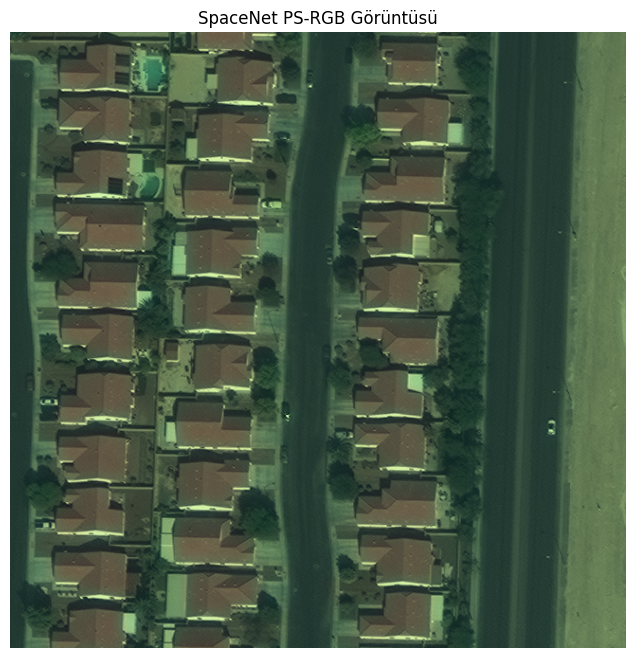

In [ ]:
# ============================================================
# CELL 11 - Örnek uydu görüntüsü
# ============================================================

with rasterio.open(sample_path) as src:

    image = src.read()[:3]

# C,H,W -> H,W,C
rgb = np.transpose(
    image,
    (1, 2, 0)
).astype(np.float32)

# Görselleştirme için normalize
rgb_min = rgb.min()
rgb_max = rgb.max()

rgb_display = (
    rgb - rgb_min
) / (
    rgb_max - rgb_min + 1e-8
)

plt.figure(figsize=(8, 8))

plt.imshow(rgb_display)

plt.title("SpaceNet PS-RGB Görüntüsü")

plt.axis("off")

plt.show()

In [ ]:
# ============================================================
# CELL 12 - Ground Truth bina maskeleri
# ============================================================

created = 0
skipped = 0

for image_id in selected_ids:

    image_filename = (
        "SN2_buildings_train_AOI_2_Vegas_"
        f"PS-RGB_img{image_id}.tif"
    )

    image_path = os.path.join(
        IMAGE_DIR,
        image_filename
    )

    geojson_filename = (
        "SN2_buildings_train_AOI_2_Vegas_"
        f"geojson_buildings_img{image_id}.geojson"
    )

    geojson_path = os.path.join(
        GEOJSON_DIR,
        geojson_filename
    )

    mask_path = os.path.join(
        MASK_DIR,
        f"mask_{image_id}.npy"
    )

    if not os.path.exists(image_path):
        skipped += 1
        continue

    if not os.path.exists(geojson_path):
        skipped += 1
        continue

    try:

        # ----------------------------------------------------
        # Görüntünün geometrik bilgisi
        # ----------------------------------------------------

        with rasterio.open(image_path) as src:

            height = src.height
            width = src.width
            transform = src.transform

        # ----------------------------------------------------
        # GeoJSON
        # ----------------------------------------------------

        with open(
            geojson_path,
            "r"
        ) as f:

            geojson = json.load(f)

        polygons = []

        for feature in geojson.get(
            "features",
            []
        ):

            geometry = feature.get(
                "geometry"
            )

            if geometry is None:
                continue

            geom = shape(geometry)

            if geom.geom_type in [
                "Polygon",
                "MultiPolygon"
            ]:

                polygons.append(
                    (geom, 1)
                )

        # ----------------------------------------------------
        # Raster mask
        # ----------------------------------------------------

        mask = rasterize(
            polygons,
            out_shape=(height, width),
            transform=transform,
            fill=0,
            dtype=np.uint8
        )

        np.save(
            mask_path,
            mask
        )

        created += 1

    except Exception as e:

        skipped += 1

        print(
            f"img{image_id} hata:",
            e
        )

print("\nMaskeler hazır.")

print(
    "Oluşturulan:",
    created
)

print(
    "Atlanan:",
    skipped
)


Maskeler hazır.
Oluşturulan: 100
Atlanan: 0


Image: (650, 650, 3)
Mask: (650, 650)
Bina pikseli: 109876
Bina oranı: 0.26006153846153846


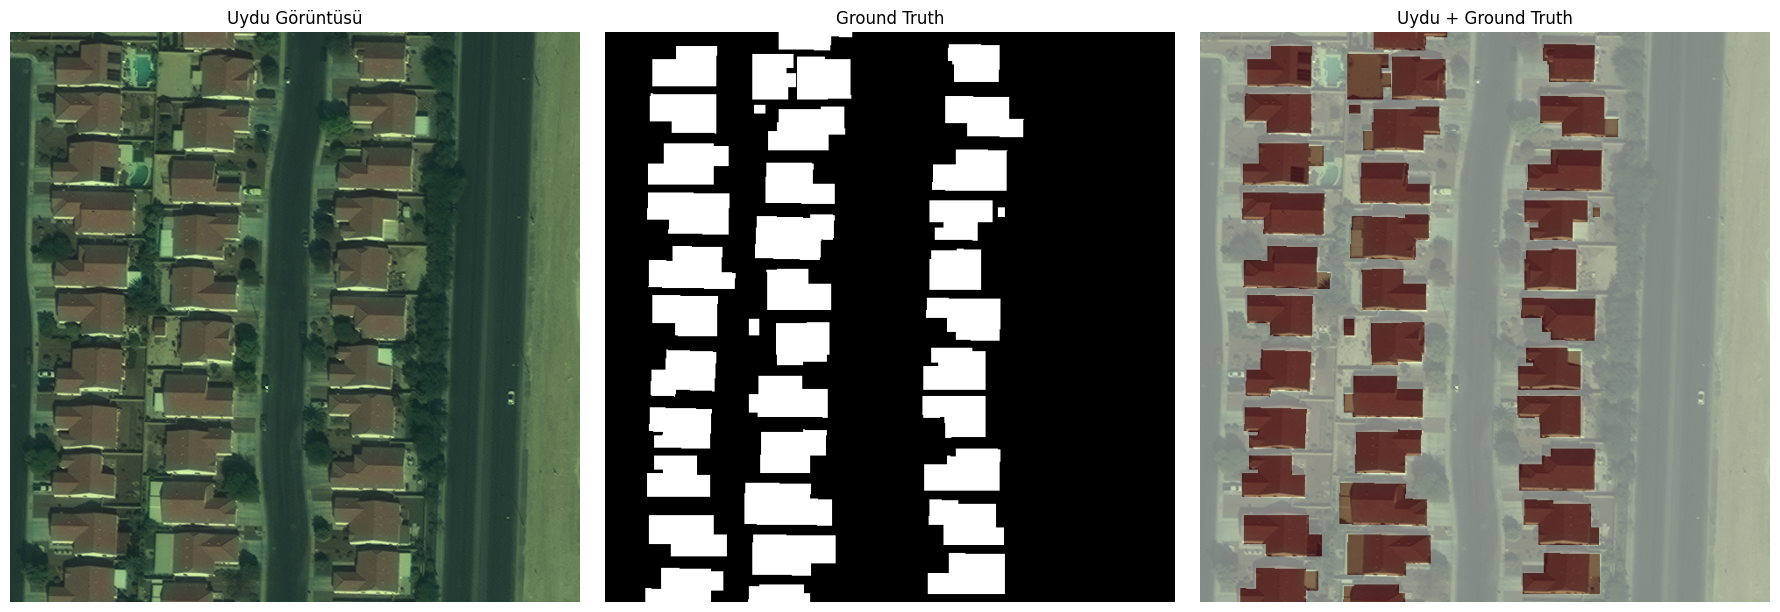

In [ ]:
# ============================================================
# CELL 13 - Ground Truth kontrolü
# ============================================================

test_image = image_files[0]

match = re.search(
    r"img(\d+)\.tif",
    os.path.basename(test_image)
)

test_id = int(match.group(1))

mask_path = os.path.join(
    MASK_DIR,
    f"mask_{test_id}.npy"
)

with rasterio.open(test_image) as src:

    image = src.read()[:3]

mask = np.load(
    mask_path
)

rgb = np.transpose(
    image,
    (1, 2, 0)
).astype(np.float32)

rgb = (
    rgb - rgb.min()
) / (
    rgb.max() - rgb.min() + 1e-8
)

print("Image:", rgb.shape)
print("Mask:", mask.shape)

print(
    "Bina pikseli:",
    mask.sum()
)

print(
    "Bina oranı:",
    mask.mean()
)

# ------------------------------------------------------------
# Görsel
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

axes[0].imshow(rgb)
axes[0].set_title("Uydu Görüntüsü")

axes[1].imshow(
    mask,
    cmap="gray"
)
axes[1].set_title("Ground Truth")

axes[2].imshow(rgb)
axes[2].imshow(
    mask,
    cmap="Reds",
    alpha=0.45
)
axes[2].set_title("Uydu + Ground Truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 14 - Geçerli görüntüleri belirle
# ============================================================

valid_samples = []

for image_id in selected_ids:

    image_filename = (
        "SN2_buildings_train_AOI_2_Vegas_"
        f"PS-RGB_img{image_id}.tif"
    )

    image_path = os.path.join(
        IMAGE_DIR,
        image_filename
    )

    mask_path = os.path.join(
        MASK_DIR,
        f"mask_{image_id}.npy"
    )

    if (
        os.path.exists(image_path)
        and
        os.path.exists(mask_path)
    ):

        valid_samples.append(
            image_id
        )

print(
    "Geçerli örnek sayısı:",
    len(valid_samples)
)

print(
    valid_samples[:20]
)

Geçerli örnek sayısı: 100
[48, 192, 200, 220, 235, 315, 327, 498, 563, 569, 611, 659, 666, 686, 712, 722, 724, 803, 893, 991]


In [ ]:
# ============================================================
# CELL 15 - Train / Validation split
# ============================================================

train_ids, val_ids = train_test_split(
    valid_samples,
    test_size=0.20,
    random_state=SEED
)

print(
    "Toplam:",
    len(valid_samples)
)

print(
    "Train:",
    len(train_ids)
)

print(
    "Validation:",
    len(val_ids)
)

print(
    "\nTrain örnekleri:",
    train_ids[:10]
)

print(
    "Validation örnekleri:",
    val_ids[:10]
)

Toplam: 100
Train: 80
Validation: 20

Train örnekleri: [3155, 5536, 1530, 2397, 4345, 722, 2065, 5949, 569, 4488]
Validation örnekleri: [5113, 2934, 4399, 2519, 2488, 2040, 1158, 5023, 611, 48]


In [ ]:
# ============================================================
# CELL 16 - Normalization fonksiyonu
# ============================================================

def normalize_image(image):

    image = image.astype(
        np.float32
    )

    # Her RGB kanalını ayrı normalize et
    for c in range(
        image.shape[0]
    ):

        band = image[c]

        min_val = band.min()
        max_val = band.max()

        if max_val > min_val:

            image[c] = (
                band - min_val
            ) / (
                max_val - min_val
            )

        else:

            image[c] = 0.0

    return image

In [ ]:
# ============================================================
# CELL 17 - Building Dataset
# ============================================================

class BuildingDataset(Dataset):

    def __init__(
        self,
        image_ids,
        image_dir,
        mask_dir,
        image_size=256,
        augment=False
    ):

        self.image_ids = image_ids
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size
        self.augment = augment

    def __len__(self):

        return len(
            self.image_ids
        )

    def __getitem__(self, idx):

        image_id = self.image_ids[idx]

        # ----------------------------------------------------
        # Dosya yolları
        # ----------------------------------------------------

        image_filename = (
            "SN2_buildings_train_AOI_2_Vegas_"
            f"PS-RGB_img{image_id}.tif"
        )

        image_path = os.path.join(
            self.image_dir,
            image_filename
        )

        mask_path = os.path.join(
            self.mask_dir,
            f"mask_{image_id}.npy"
        )

        # ----------------------------------------------------
        # Görüntü
        # ----------------------------------------------------

        with rasterio.open(
            image_path
        ) as src:

            image = src.read()[:3]

        image = normalize_image(
            image
        )

        # ----------------------------------------------------
        # Maske
        # ----------------------------------------------------

        mask = np.load(
            mask_path
        ).astype(
            np.float32
        )

        # ----------------------------------------------------
        # Tensor
        # ----------------------------------------------------

        image = torch.from_numpy(
            image
        )

        mask = torch.from_numpy(
            mask
        ).unsqueeze(0)

        # ----------------------------------------------------
        # 256x256
        # ----------------------------------------------------

        image = F.interpolate(
            image.unsqueeze(0),
            size=(
                self.image_size,
                self.image_size
            ),
            mode="bilinear",
            align_corners=False
        )[0]

        mask = F.interpolate(
            mask.unsqueeze(0),
            size=(
                self.image_size,
                self.image_size
            ),
            mode="nearest"
        )[0]

        # ----------------------------------------------------
        # Data augmentation
        # ----------------------------------------------------

        if self.augment:

            # Horizontal flip
            if random.random() < 0.5:

                image = torch.flip(
                    image,
                    dims=[2]
                )

                mask = torch.flip(
                    mask,
                    dims=[2]
                )

            # Vertical flip
            if random.random() < 0.5:

                image = torch.flip(
                    image,
                    dims=[1]
                )

                mask = torch.flip(
                    mask,
                    dims=[1]
                )

        return image, mask


train_dataset = BuildingDataset(
    train_ids,
    IMAGE_DIR,
    MASK_DIR,
    image_size=IMAGE_SIZE,
    augment=True
)

val_dataset = BuildingDataset(
    val_ids,
    IMAGE_DIR,
    MASK_DIR,
    image_size=IMAGE_SIZE,
    augment=False
)

print(
    "Train dataset:",
    len(train_dataset)
)

print(
    "Validation dataset:",
    len(val_dataset)
)

Train dataset: 80
Validation dataset: 20


In [ ]:
# ============================================================
# CELL 18 - DataLoaders
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, masks = next(
    iter(train_loader)
)

print(
    "Image batch:",
    images.shape
)

print(
    "Mask batch:",
    masks.shape
)

Image batch: torch.Size([4, 3, 256, 256])
Mask batch: torch.Size([4, 1, 256, 256])


In [ ]:
# ============================================================
# CELL 19 - U-Net
# ============================================================

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        dropout=0.0
    ):

        super().__init__()

        layers = [

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        ]

        if dropout > 0:

            layers.append(
                nn.Dropout2d(
                    dropout
                )
            )

        self.block = nn.Sequential(
            *layers
        )

    def forward(self, x):

        return self.block(x)


class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        self.enc1 = DoubleConv(
            3,
            32
        )

        self.enc2 = DoubleConv(
            32,
            64
        )

        self.enc3 = DoubleConv(
            64,
            128
        )

        self.pool = nn.MaxPool2d(
            2
        )

        # ----------------------------------------------------
        # Bottleneck
        # ----------------------------------------------------

        self.bottleneck = DoubleConv(
            128,
            256,
            dropout=0.20
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.up3 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            256,
            128
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            64,
            32
        )

        # ----------------------------------------------------
        # Output
        # ----------------------------------------------------

        self.output = nn.Conv2d(
            32,
            1,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool(e3)
        )

        # Decoder
        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        return self.output(d1)


model = UNet().to(DEVICE)

parameter_count = sum(
    p.numel()
    for p in model.parameters()
)

print(
    "Model parametre sayısı:",
    parameter_count
)

Model parametre sayısı: 1928417


In [ ]:
# ============================================================
# CELL 19 - U-Net
# ============================================================

class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        dropout=0.0
    ):

        super().__init__()

        layers = [

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            )
        ]

        if dropout > 0:

            layers.append(
                nn.Dropout2d(
                    dropout
                )
            )

        self.block = nn.Sequential(
            *layers
        )

    def forward(self, x):

        return self.block(x)


class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        self.enc1 = DoubleConv(
            3,
            32
        )

        self.enc2 = DoubleConv(
            32,
            64
        )

        self.enc3 = DoubleConv(
            64,
            128
        )

        self.pool = nn.MaxPool2d(
            2
        )

        # ----------------------------------------------------
        # Bottleneck
        # ----------------------------------------------------

        self.bottleneck = DoubleConv(
            128,
            256,
            dropout=0.20
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.up3 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            256,
            128
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            64,
            32
        )

        # ----------------------------------------------------
        # Output
        # ----------------------------------------------------

        self.output = nn.Conv2d(
            32,
            1,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool(e3)
        )

        # Decoder
        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        return self.output(d1)


model = UNet().to(DEVICE)

parameter_count = sum(
    p.numel()
    for p in model.parameters()
)

print(
    "Model parametre sayısı:",
    parameter_count
)

Model parametre sayısı: 1928417


In [ ]:
# ============================================================
# CELL 20 - Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        smooth=1.0
    ):

        super().__init__()

        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probabilities = torch.sigmoid(
            logits
        )

        probabilities = probabilities.contiguous()
        targets = targets.contiguous()

        intersection = (
            probabilities * targets
        ).sum(
            dim=(2, 3)
        )

        denominator = (
            probabilities.sum(
                dim=(2, 3)
            )
            +
            targets.sum(
                dim=(2, 3)
            )
        )

        dice = (
            2 * intersection
            + self.smooth
        ) / (
            denominator
            + self.smooth
        )

        return (
            1 - dice
        ).mean()

In [ ]:
# ============================================================
# CELL 21 - Combined Loss
# ============================================================

bce_loss = nn.BCEWithLogitsLoss()

dice_loss = DiceLoss()


def combined_loss(
    logits,
    targets
):

    bce = bce_loss(
        logits,
        targets
    )

    dice = dice_loss(
        logits,
        targets
    )

    return (
        0.5 * bce
        +
        0.5 * dice
    )


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss ve optimizer hazır.")

Loss ve optimizer hazır.


In [ ]:
# ============================================================
# CELL 22 - IoU
# ============================================================

def calculate_iou(
    probabilities,
    targets,
    threshold=0.5
):

    predictions = (
        probabilities >= threshold
    ).float()

    targets = (
        targets >= 0.5
    ).float()

    intersection = (
        predictions * targets
    ).sum(
        dim=(1, 2, 3)
    )

    union = (
        (
            predictions
            +
            targets
        ) > 0
    ).float().sum(
        dim=(1, 2, 3)
    )

    iou = torch.where(
        union > 0,
        intersection / union,
        torch.ones_like(union)
    )

    return iou.mean().item()

In [ ]:
# ============================================================
# CELL 23 - Model Training
# ============================================================

best_val_loss = float("inf")

patience = 5
patience_counter = 0

train_losses = []
val_losses = []

train_ious = []
val_ious = []

BEST_MODEL_PATH = os.path.join(
    RESULT_DIR,
    "best_unet_model.pth"
)

for epoch in range(
    EPOCHS
):

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    running_train_loss = 0.0
    running_train_iou = 0.0

    for images, masks in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = combined_loss(
            outputs,
            masks
        )

        loss.backward()

        optimizer.step()

        probabilities = torch.sigmoid(
            outputs
        )

        iou = calculate_iou(
            probabilities,
            masks,
            threshold=0.5
        )

        running_train_loss += (
            loss.item()
        )

        running_train_iou += iou

    train_loss = (
        running_train_loss
        /
        len(train_loader)
    )

    train_iou = (
        running_train_iou
        /
        len(train_loader)
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    running_val_loss = 0.0
    running_val_iou = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            masks = masks.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(
                images
            )

            loss = combined_loss(
                outputs,
                masks
            )

            probabilities = torch.sigmoid(
                outputs
            )

            iou = calculate_iou(
                probabilities,
                masks,
                threshold=0.5
            )

            running_val_loss += (
                loss.item()
            )

            running_val_iou += iou

    val_loss = (
        running_val_loss
        /
        len(val_loader)
    )

    val_iou = (
        running_val_iou
        /
        len(val_loader)
    )

    # ========================================================
    # Kayıt
    # ========================================================

    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    train_ious.append(
        train_iou
    )

    val_ious.append(
        val_iou
    )

    scheduler.step(
        val_loss
    )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train IoU: {train_iou:.4f} | "
        f"Val IoU: {val_iou:.4f}"
    )

    # ========================================================
    # En iyi modeli kaydet
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        patience_counter = 0

        print(
            "   ✓ En iyi model kaydedildi."
        )

    else:

        patience_counter += 1

    # ========================================================
    # Early stopping
    # ========================================================

    if patience_counter >= patience:

        print(
            "\nEarly stopping uygulandı."
        )

        break

print(
    "\nEğitim tamamlandı."
)

print(
    "En iyi model:",
    BEST_MODEL_PATH
)

Epoch 01/20 | Train Loss: 0.6055 | Val Loss: 0.6222 | Train IoU: 0.3512 | Val IoU: 0.2114
   ✓ En iyi model kaydedildi.
Epoch 02/20 | Train Loss: 0.5274 | Val Loss: 0.5598 | Train IoU: 0.4201 | Val IoU: 0.1528
   ✓ En iyi model kaydedildi.
Epoch 03/20 | Train Loss: 0.4906 | Val Loss: 0.4826 | Train IoU: 0.4340 | Val IoU: 0.4453
   ✓ En iyi model kaydedildi.
Epoch 04/20 | Train Loss: 0.4548 | Val Loss: 0.5136 | Train IoU: 0.4566 | Val IoU: 0.4414
Epoch 05/20 | Train Loss: 0.4286 | Val Loss: 0.4106 | Train IoU: 0.4614 | Val IoU: 0.4676
   ✓ En iyi model kaydedildi.
Epoch 06/20 | Train Loss: 0.3932 | Val Loss: 0.3881 | Train IoU: 0.5075 | Val IoU: 0.4956
   ✓ En iyi model kaydedildi.
Epoch 07/20 | Train Loss: 0.3968 | Val Loss: 0.4342 | Train IoU: 0.4812 | Val IoU: 0.4661
Epoch 08/20 | Train Loss: 0.3538 | Val Loss: 0.3644 | Train IoU: 0.5289 | Val IoU: 0.4838
   ✓ En iyi model kaydedildi.
Epoch 09/20 | Train Loss: 0.3535 | Val Loss: 0.3422 | Train IoU: 0.5098 | Val IoU: 0.4974
   ✓ En iy

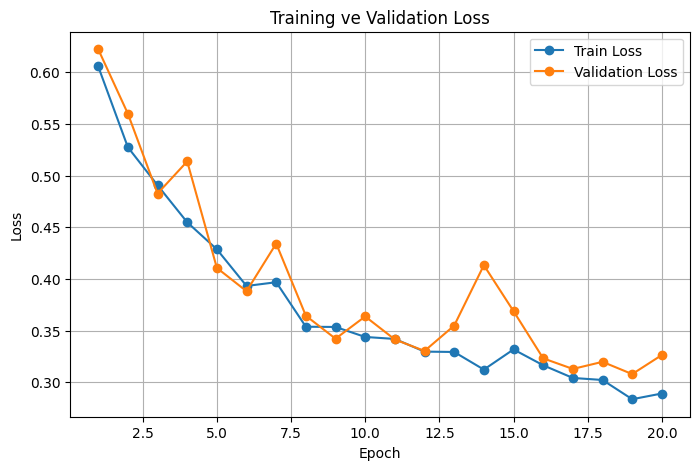

In [ ]:
# ============================================================
# CELL 24 - Training / Validation Loss
# ============================================================

epochs = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training ve Validation Loss"
)

plt.legend()

plt.grid()

plt.show()

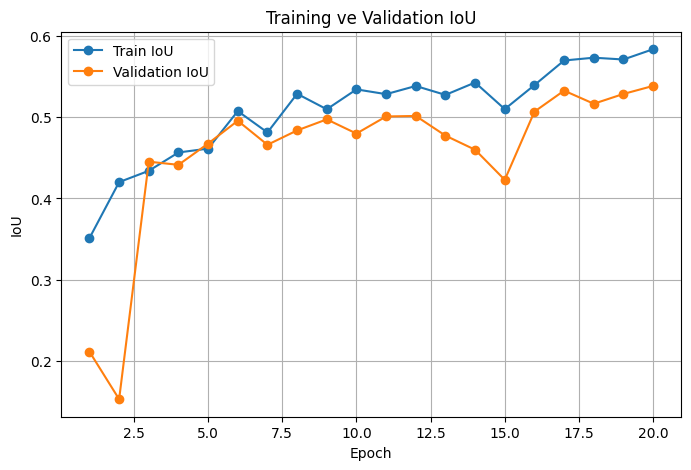

In [ ]:
# ============================================================
# CELL 25 - IoU grafiği
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs,
    train_ious,
    marker="o",
    label="Train IoU"
)

plt.plot(
    epochs,
    val_ious,
    marker="o",
    label="Validation IoU"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")

plt.title(
    "Training ve Validation IoU"
)

plt.legend()

plt.grid()

plt.show()

In [ ]:
# ============================================================
# CELL 26 - Best model
# ============================================================

model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE
    )
)

model = model.to(
    DEVICE
)

model.eval()

print(
    "En iyi model yüklendi."
)

En iyi model yüklendi.


In [ ]:
# ============================================================
# CELL 27 - Tek görüntüde AI tahmini
# ============================================================

def predict_image(
    image_id
):

    image_filename = (
        "SN2_buildings_train_AOI_2_Vegas_"
        f"PS-RGB_img{image_id}.tif"
    )

    image_path = os.path.join(
        IMAGE_DIR,
        image_filename
    )

    mask_path = os.path.join(
        MASK_DIR,
        f"mask_{image_id}.npy"
    )

    # --------------------------------------------------------
    # Görüntü
    # --------------------------------------------------------

    with rasterio.open(
        image_path
    ) as src:

        image = src.read()[:3]

    original_image = image.copy()

    image = normalize_image(
        image
    )

    image_tensor = torch.from_numpy(
        image
    ).float()

    image_tensor = F.interpolate(
        image_tensor.unsqueeze(0),
        size=(
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        mode="bilinear",
        align_corners=False
    )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    with torch.no_grad():

        logits = model(
            image_tensor.to(DEVICE)
        )

        probability = torch.sigmoid(
            logits
        )[0, 0].cpu().numpy()

    # --------------------------------------------------------
    # Ground Truth
    # --------------------------------------------------------

    true_mask = np.load(
        mask_path
    ).astype(
        np.float32
    )

    true_mask = F.interpolate(
        torch.from_numpy(
            true_mask
        ).unsqueeze(0).unsqueeze(0),
        size=(
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        mode="nearest"
    )[0, 0].numpy()

    return (
        original_image,
        true_mask,
        probability
    )

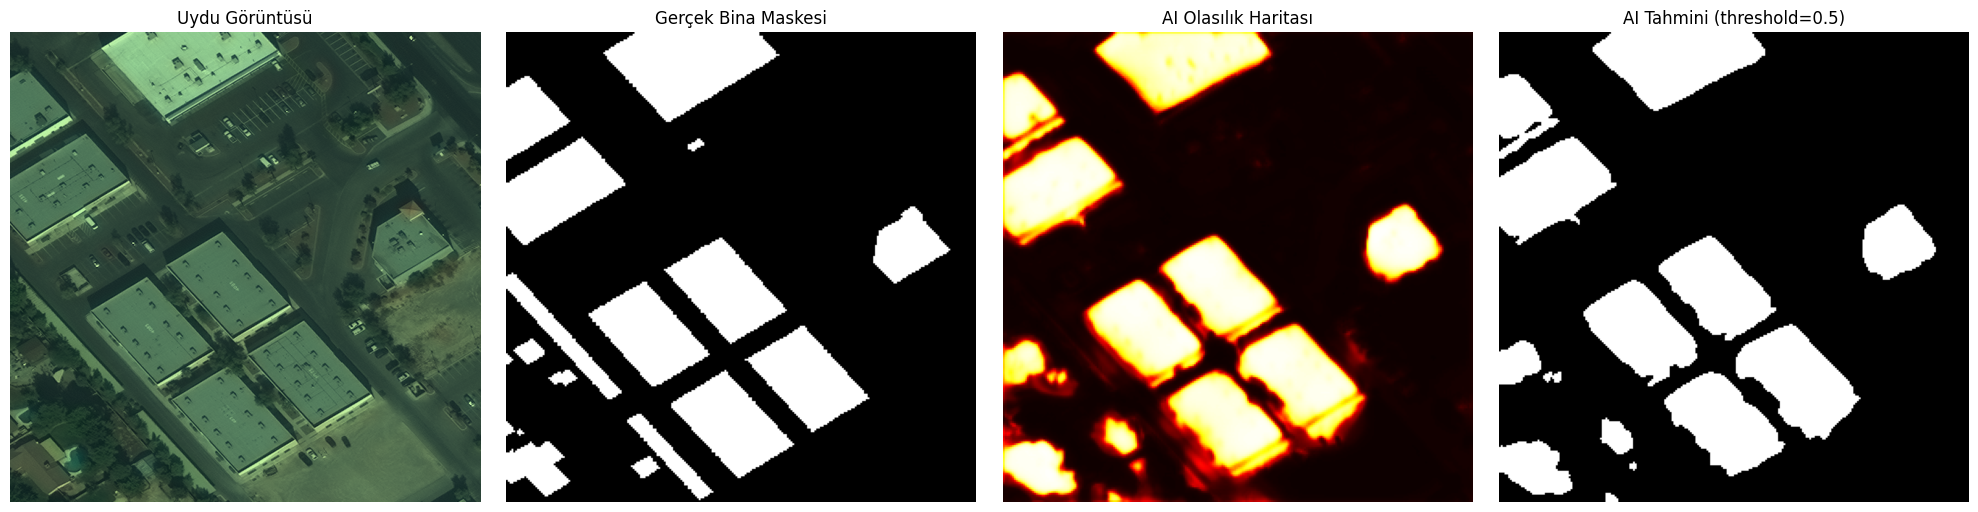

AI minimum: 0.0033134317
AI maksimum: 0.9950276
AI ortalama: 0.25709707


In [ ]:
# ============================================================
# CELL 28 - AI tahmini görseli
# ============================================================

test_id = val_ids[1]

original_image, true_mask, probability = predict_image(
    test_id
)

# ------------------------------------------------------------
# RGB gösterim
# ------------------------------------------------------------

rgb = np.transpose(
    original_image,
    (1, 2, 0)
).astype(np.float32)

rgb = (
    rgb - rgb.min()
) / (
    rgb.max() - rgb.min() + 1e-8
)

# ------------------------------------------------------------
# Binary prediction
# ------------------------------------------------------------

threshold = 0.5

pred_binary = (
    probability >= threshold
)

# ------------------------------------------------------------
# Grafik
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

axes[0].imshow(rgb)
axes[0].set_title(
    "Uydu Görüntüsü"
)

axes[1].imshow(
    true_mask,
    cmap="gray"
)

axes[1].set_title(
    "Gerçek Bina Maskesi"
)

axes[2].imshow(
    probability,
    cmap="hot",
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "AI Olasılık Haritası"
)

axes[3].imshow(
    pred_binary,
    cmap="gray"
)

axes[3].set_title(
    f"AI Tahmini (threshold={threshold})"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(
    "AI minimum:",
    probability.min()
)

print(
    "AI maksimum:",
    probability.max()
)

print(
    "AI ortalama:",
    probability.mean()
)

In [ ]:
# ============================================================
# CELL 29 - Tek görüntü IoU
# ============================================================

def numpy_iou(
    prediction,
    target,
    threshold=0.5
):

    pred_binary = (
        prediction >= threshold
    )

    target_binary = (
        target >= 0.5
    )

    intersection = np.logical_and(
        pred_binary,
        target_binary
    ).sum()

    union = np.logical_or(
        pred_binary,
        target_binary
    ).sum()

    if union == 0:

        return 1.0

    return (
        intersection / union
    )


for threshold in [
    0.3,
    0.4,
    0.5,
    0.6,
    0.7
]:

    iou = numpy_iou(
        probability,
        true_mask,
        threshold
    )

    print(
        f"Threshold {threshold:.1f} → "
        f"IoU = {iou:.4f}"
    )

Threshold 0.3 → IoU = 0.7592
Threshold 0.4 → IoU = 0.7699
Threshold 0.5 → IoU = 0.7709
Threshold 0.6 → IoU = 0.7676
Threshold 0.7 → IoU = 0.7492


In [ ]:
# ============================================================
# CELL 30 - Tüm validation setinde IoU
# ============================================================

thresholds = [
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7
]

all_results = []

for image_id in val_ids:

    try:

        _, true_mask, probability = predict_image(
            image_id
        )

        row = {
            "image_id": image_id
        }

        for threshold in thresholds:

            iou = numpy_iou(
                probability,
                true_mask,
                threshold
            )

            row[
                f"IoU_{threshold}"
            ] = iou

        all_results.append(
            row
        )

    except Exception as e:

        print(
            "Hata:",
            image_id,
            e
        )


validation_results = pd.DataFrame(
    all_results
)

display(
    validation_results.head()
)

# ------------------------------------------------------------
# Ortalama IoU
# ------------------------------------------------------------

print(
    "\nOrtalama IoU:"
)

for threshold in thresholds:

    mean_iou = validation_results[
        f"IoU_{threshold}"
    ].mean()

    print(
        f"Threshold {threshold:.1f}: "
        f"{mean_iou:.4f}"
    )# ============================================================
# CELL 30 - Tüm validation setinde IoU
# ============================================================

thresholds = [
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7
]

all_results = []

for image_id in val_ids:

    try:

        _, true_mask, probability = predict_image(
            image_id
        )

        row = {
            "image_id": image_id
        }

        for threshold in thresholds:

            iou = numpy_iou(
                probability,
                true_mask,
                threshold
            )

            row[
                f"IoU_{threshold}"
            ] = iou

        all_results.append(
            row
        )

    except Exception as e:

        print(
            "Hata:",
            image_id,
            e
        )


validation_results = pd.DataFrame(
    all_results
)

display(
    validation_results.head()
)

# ------------------------------------------------------------
# Ortalama IoU
# ------------------------------------------------------------

print(
    "\nOrtalama IoU:"
)

for threshold in thresholds:

    mean_iou = validation_results[
        f"IoU_{threshold}"
    ].mean()

    print(
        f"Threshold {threshold:.1f}: "
        f"{mean_iou:.4f}"
    )

,image_id,IoU_0.2,IoU_0.3,IoU_0.4,IoU_0.5,IoU_0.6,IoU_0.7
0,5113,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2934,0.725097,0.759203,0.769916,0.770911,0.767638,0.749163
2,4399,0.625765,0.646676,0.662077,0.674800,0.686082,0.707072
3,2519,0.736058,0.728971,0.719439,0.711991,0.699676,0.673888
4,2488,0.644465,0.665198,0.669723,0.675904,0.676984,0.665769



Ortalama IoU:
Threshold 0.2: 0.5089
Threshold 0.3: 0.5225
Threshold 0.4: 0.5266
Threshold 0.5: 0.5287
Threshold 0.6: 0.5273
Threshold 0.7: 0.5198


,image_id,IoU_0.2,IoU_0.3,IoU_0.4,IoU_0.5,IoU_0.6,IoU_0.7
0,5113,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2934,0.725097,0.759203,0.769916,0.770911,0.767638,0.749163
2,4399,0.625765,0.646676,0.662077,0.674800,0.686082,0.707072
3,2519,0.736058,0.728971,0.719439,0.711991,0.699676,0.673888
4,2488,0.644465,0.665198,0.669723,0.675904,0.676984,0.665769



Ortalama IoU:
Threshold 0.2: 0.5089
Threshold 0.3: 0.5225
Threshold 0.4: 0.5266
Threshold 0.5: 0.5287
Threshold 0.6: 0.5273
Threshold 0.7: 0.5198


In [ ]:
# ============================================================
# CELL 31 - En iyi threshold
# ============================================================

threshold_scores = {}

for threshold in thresholds:

    score = validation_results[
        f"IoU_{threshold}"
    ].mean()

    threshold_scores[
        threshold
    ] = score

best_threshold = max(
    threshold_scores,
    key=threshold_scores.get
)

best_mean_iou = threshold_scores[
    best_threshold
]

print(
    "En iyi threshold:",
    best_threshold
)

print(
    "En iyi ortalama IoU:",
    round(
        best_mean_iou,
        4
    )
)

En iyi threshold: 0.5
En iyi ortalama IoU: 0.5287


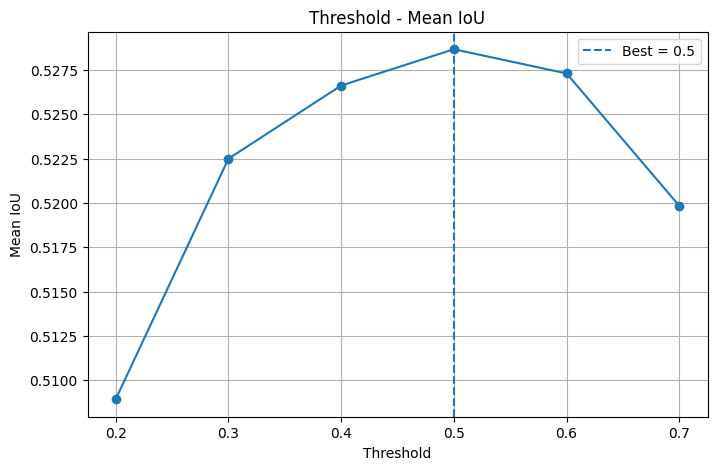

In [ ]:
# ============================================================
# CELL 32 - Threshold / IoU
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    list(threshold_scores.keys()),
    list(threshold_scores.values()),
    marker="o"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=(
        f"Best = {best_threshold}"
    )
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Mean IoU"
)

plt.title(
    "Threshold - Mean IoU"
)

plt.legend()

plt.grid()

plt.show()

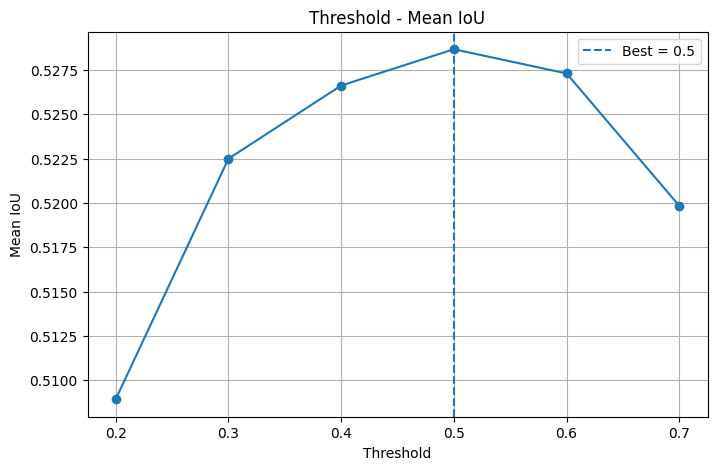

In [ ]:
# ============================================================
# CELL 32 - Threshold / IoU
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    list(threshold_scores.keys()),
    list(threshold_scores.values()),
    marker="o"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=(
        f"Best = {best_threshold}"
    )
)

plt.xlabel(
    "Threshold"
)

plt.ylabel(
    "Mean IoU"
)

plt.title(
    "Threshold - Mean IoU"
)

plt.legend()

plt.grid()

plt.show()

In [ ]:
print("Sütun isimleri:")
print(validation_results.columns.tolist())

print("\nİlk 5 satır:")
print(validation_results.head())

Sütun isimleri:
['image_id', 'IoU_0.2', 'IoU_0.3', 'IoU_0.4', 'IoU_0.5', 'IoU_0.6', 'IoU_0.7']

İlk 5 satır:
   image_id   IoU_0.2   IoU_0.3   IoU_0.4   IoU_0.5   IoU_0.6   IoU_0.7
0      5113  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000
1      2934  0.725097  0.759203  0.769916  0.770911  0.767638  0.749163
2      4399  0.625765  0.646676  0.662077  0.674800  0.686082  0.707072
3      2519  0.736058  0.728971  0.719439  0.711991  0.699676  0.673888
4      2488  0.644465  0.665198  0.669723  0.675904  0.676984  0.665769


In [ ]:
# IoU_0.5 değerine göre en iyi görüntüyü seç
best_row = validation_results.sort_values(
    "IoU_0.5",
    ascending=False
).iloc[0]

test_id = int(best_row["image_id"])

print("Seçilen görüntü ID:", test_id)
print("IoU (threshold=0.5):", best_row["IoU_0.5"])

Seçilen görüntü ID: 2934
IoU (threshold=0.5): 0.7709106328845542


In [ ]:
worst_row = validation_results.sort_values(
    "IoU_0.5",
    ascending=True
).iloc[0]

worst_test_id = int(worst_row["image_id"])

print("En kötü görüntü ID:", worst_test_id)
print("IoU (threshold=0.5):", worst_row["IoU_0.5"])

En kötü görüntü ID: 5113
IoU (threshold=0.5): 0.0


Görüntü boyutu: (3, 650, 650)
Gerçek maske boyutu: (256, 256)
Tahmin boyutu: (256, 256)


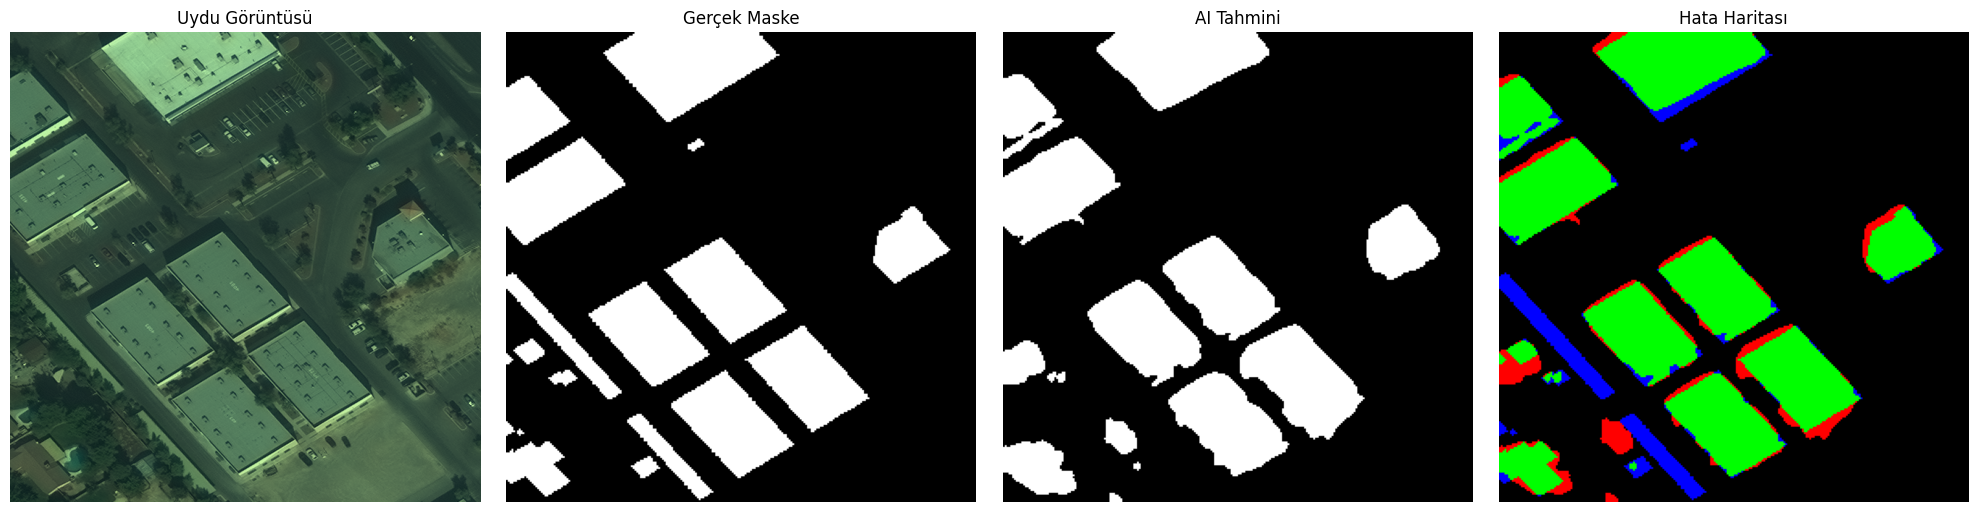

Görüntü ID: 2934
IoU (threshold=0.5): 0.7709106328845542
Gerçek bina pikseli: 16772
Tahmin edilen bina pikseli: 16638
Doğru bina pikseli (TP): 14544
Yanlış bina pikseli (FP): 2094
Kaçırılan bina pikseli (FN): 2228


In [ ]:

# ============================================================
# CELL 34 - Hata haritası
# ============================================================

# IoU değeri yüksek olan görüntüyü seç
best_row = validation_results.sort_values(
    "IoU_0.5",
    ascending=False
).iloc[0]

test_id = int(best_row["image_id"])

# Görüntü, gerçek maske ve model tahmini
original_image, true_mask, probability = predict_image(test_id)

# En iyi threshold'u kullan
pred_binary = probability >= best_threshold

# Maskeleri Boolean hale getir
true_mask = np.asarray(true_mask).squeeze() > 0
pred_binary = np.asarray(pred_binary).squeeze().astype(bool)

# Boyut kontrolü
print("Görüntü boyutu:", original_image.shape)
print("Gerçek maske boyutu:", true_mask.shape)
print("Tahmin boyutu:", pred_binary.shape)

# ============================================================
# HATA SINIFLARI
# ============================================================

true_positive = pred_binary & true_mask
false_positive = pred_binary & (~true_mask)
false_negative = (~pred_binary) & true_mask

# Yeşil: doğru bina tahmini
# Kırmızı: yanlış bina tahmini
# Mavi: kaçırılan bina
error_map = np.zeros(
    (*true_mask.shape, 3),
    dtype=np.float32
)

error_map[true_positive] = [0, 1, 0]
error_map[false_positive] = [1, 0, 0]
error_map[false_negative] = [0, 0, 1]

# ============================================================
# GÖRSELLEŞTİRME
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# RGB görüntüsü
rgb = np.transpose(original_image, (1, 2, 0)).astype(np.float32)

rgb_min = rgb.min()
rgb_max = rgb.max()

rgb = (rgb - rgb_min) / (rgb_max - rgb_min + 1e-8)

axes[0].imshow(rgb)
axes[0].set_title("Uydu Görüntüsü")

axes[1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Gerçek Maske")

axes[2].imshow(pred_binary, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("AI Tahmini")

axes[3].imshow(error_map)
axes[3].set_title("Hata Haritası")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# SONUÇLAR
# ============================================================

print("Görüntü ID:", test_id)
print("IoU (threshold=0.5):", best_row["IoU_0.5"])
print("Gerçek bina pikseli:", int(true_mask.sum()))
print("Tahmin edilen bina pikseli:", int(pred_binary.sum()))
print("Doğru bina pikseli (TP):", int(true_positive.sum()))
print("Yanlış bina pikseli (FP):", int(false_positive.sum()))
print("Kaçırılan bina pikseli (FN):", int(false_negative.sum()))

In [ ]:
# ============================================================
# CELL 35 - Monte Carlo Dropout Uncertainty
# ============================================================

def enable_dropout(
    model
):

    for module in model.modules():

        if isinstance(
            module,
            nn.Dropout2d
        ):

            module.train()


def monte_carlo_prediction(
    image_id,
    n_samples=20
):

    image_filename = (
        "SN2_buildings_train_AOI_2_Vegas_"
        f"PS-RGB_img{image_id}.tif"
    )

    image_path = os.path.join(
        IMAGE_DIR,
        image_filename
    )

    with rasterio.open(
        image_path
    ) as src:

        image = src.read()[:3]

    image = normalize_image(
        image
    )

    image_tensor = torch.from_numpy(
        image
    ).float()

    image_tensor = F.interpolate(
        image_tensor.unsqueeze(0),
        size=(
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        mode="bilinear",
        align_corners=False
    ).to(DEVICE)

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model.eval()

    enable_dropout(
        model
    )

    predictions = []

    with torch.no_grad():

        for _ in range(
            n_samples
        ):

            logits = model(
                image_tensor
            )

            probability = torch.sigmoid(
                logits
            )

            predictions.append(
                probability
                [0, 0]
                .cpu()
                .numpy()
            )

    predictions = np.stack(
        predictions
    )

    mean_prediction = predictions.mean(
        axis=0
    )

    uncertainty = predictions.std(
        axis=0
    )

    return (
        mean_prediction,
        uncertainty
    )

Prediction min: 0.003309647
Prediction max: 0.9949436
Prediction mean: 0.25767154

Uncertainty min: 2.1032216e-05
Uncertainty max: 0.14006111
Uncertainty mean: 0.00895441


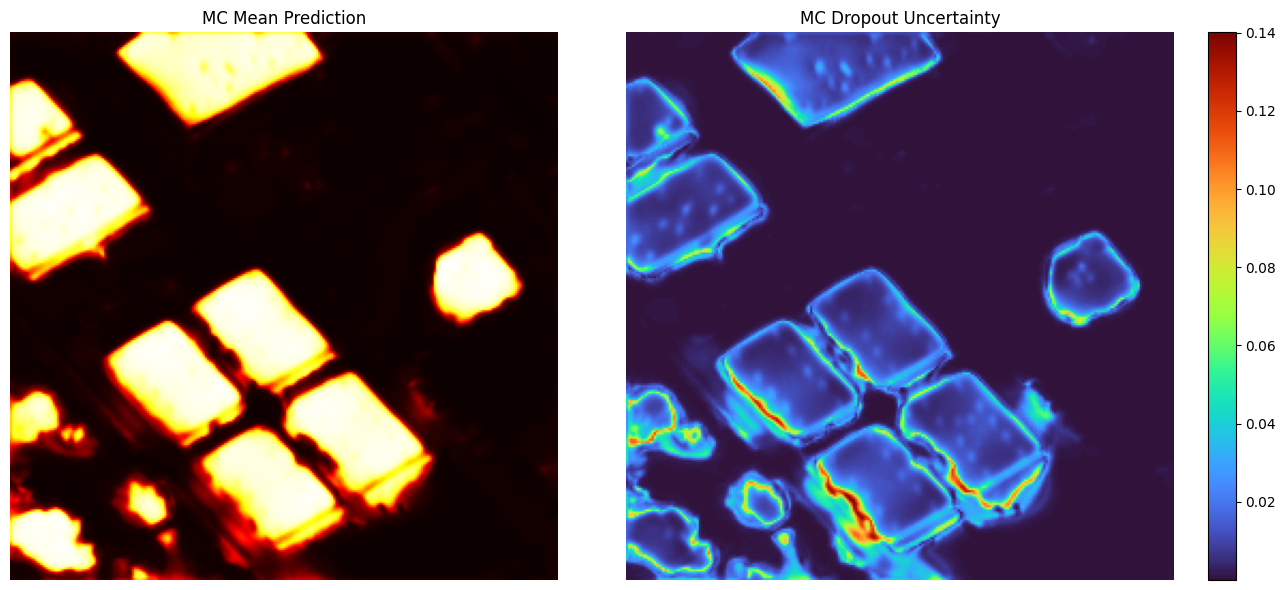

In [ ]:
# ============================================================
# CELL 36 - Uncertainty Map
# ============================================================

mc_prediction, uncertainty = monte_carlo_prediction(
    test_id,
    n_samples=20
)

print(
    "Prediction min:",
    mc_prediction.min()
)

print(
    "Prediction max:",
    mc_prediction.max()
)

print(
    "Prediction mean:",
    mc_prediction.mean()
)

print(
    "\nUncertainty min:",
    uncertainty.min()
)

print(
    "Uncertainty max:",
    uncertainty.max()
)

print(
    "Uncertainty mean:",
    uncertainty.mean()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

axes[0].imshow(
    mc_prediction,
    cmap="hot",
    vmin=0,
    vmax=1
)

axes[0].set_title(
    "MC Mean Prediction"
)

im = axes[1].imshow(
    uncertainty,
    cmap="turbo"
)

axes[1].set_title(
    "MC Dropout Uncertainty"
)

plt.colorbar(
    im,
    ax=axes[1]
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 37 - Uncertainty / Error ilişkisi
# ============================================================

pred_binary = (
    mc_prediction >= best_threshold
)

error = (
    pred_binary
    !=
    (true_mask >= 0.5)
)

uncertainty_flat = (
    uncertainty.flatten()
)

error_flat = (
    error.flatten()
    .astype(np.uint8)
)

correlation = np.corrcoef(
    uncertainty_flat,
    error_flat
)[0, 1]

print(
    "Uncertainty - Error korelasyonu:",
    round(
        float(correlation),
        4
    )
)

# ------------------------------------------------------------
# Belirsizlik seviyelerine göre hata
# ------------------------------------------------------------

bins = [
    0.0,
    0.01,
    0.02,
    0.05,
    0.10,
    1.0
]

print(
    "\nUncertainty aralığı | Piksel | Hata"
)

print(
    "-" * 45
)

for low, high in zip(
    bins[:-1],
    bins[1:]
):

    selected = (
        (uncertainty_flat >= low)
        &
        (uncertainty_flat < high)
    )

    count = selected.sum()

    if count > 0:

        error_rate = (
            error_flat[selected].mean()
        )

        print(
            f"{low:.2f} - {high:.2f}"
            f" | {count:7d}"
            f" | {error_rate:.4f}"
        )

Uncertainty - Error korelasyonu: 0.3226

Uncertainty aralığı | Piksel | Hata
---------------------------------------------
0.00 - 0.01 |   48308 | 0.0277
0.01 - 0.02 |    7529 | 0.0972
0.02 - 0.05 |    7415 | 0.1864
0.05 - 0.10 |    1969 | 0.3819
0.10 - 1.00 |     315 | 0.4349


In [ ]:
# ============================================================
# CELL 38 - Sonuçları kaydet
# ============================================================

validation_path = os.path.join(
    RESULT_DIR,
    "validation_results.csv"
)

validation_results.to_csv(
    validation_path,
    index=False
)

threshold_df = pd.DataFrame({
    "threshold": list(
        threshold_scores.keys()
    ),
    "mean_IoU": list(
        threshold_scores.values()
    )
})

threshold_path = os.path.join(
    RESULT_DIR,
    "threshold_results.csv"
)

threshold_df.to_csv(
    threshold_path,
    index=False
)

print(
    "Validation sonuçları:",
    validation_path
)

print(
    "Threshold sonuçları:",
    threshold_path
)

Validation sonuçları: /content/geoai_project/results/validation_results.csv
Threshold sonuçları: /content/geoai_project/results/threshold_results.csv


In [ ]:
# ============================================================
# CELL 38 - Sonuçları kaydet
# ============================================================

validation_path = os.path.join(
    RESULT_DIR,
    "validation_results.csv"
)

validation_results.to_csv(
    validation_path,
    index=False
)

threshold_df = pd.DataFrame({
    "threshold": list(
        threshold_scores.keys()
    ),
    "mean_IoU": list(
        threshold_scores.values()
    )
})

threshold_path = os.path.join(
    RESULT_DIR,
    "threshold_results.csv"
)

threshold_df.to_csv(
    threshold_path,
    index=False
)

print(
    "Validation sonuçları:",
    validation_path
)

print(
    "Threshold sonuçları:",
    threshold_path
)

Validation sonuçları: /content/geoai_project/results/validation_results.csv
Threshold sonuçları: /content/geoai_project/results/threshold_results.csv


In [ ]:
# ============================================================
# CELL 40 - Final proje özeti
# ============================================================

print("=" * 60)
print("       GEOAI QUALITY CONTROL - FINAL SUMMARY")
print("=" * 60)

print(
    "\nDataset"
)

print(
    "Toplam görüntü:",
    len(valid_samples)
)

print(
    "Train:",
    len(train_ids)
)

print(
    "Validation:",
    len(val_ids)
)

print(
    "\nModel"
)

print(
    "Architecture: U-Net"
)

print(
    "Input size:",
    f"{IMAGE_SIZE}x{IMAGE_SIZE}"
)

print(
    "Loss: BCE + Dice"
)

print(
    "Epoch:",
    len(train_losses)
)

print(
    "Parameters:",
    parameter_count
)

print(
    "\nPerformance"
)

print(
    "Best threshold:",
    best_threshold
)

print(
    "Mean IoU:",
    round(
        best_mean_iou,
        4
    )
)

print(
    "\nFiles"
)
'''
print(
    "Model:",
    FINAL_MODEL_PATH
)
'''
print(
    "Validation:",
    validation_path
)

print(
    "Threshold:",
    threshold_path
)

print("=" * 60)

       GEOAI QUALITY CONTROL - FINAL SUMMARY

Dataset
Toplam görüntü: 100
Train: 69
Validation: 16

Model
Architecture: U-Net
Input size: 256x256
Loss: BCE + Dice
Epoch: 20
Parameters: 1928417

Performance
Best threshold: 0.5
Mean IoU: 0.5287

Files
Validation: /content/geoai_project/results/validation_results.csv
Threshold: /content/geoai_project/results/threshold_results.csv


In [ ]:
# devamı